/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encounter

Supply Chain (stockout risk)         acc=0.998  prec=0.995  recall=0.997  f1=0.996  auc=1.0
BFSI (fraud)                         acc=1.0  prec=0.999  recall=1.0  f1=1.0  auc=1.0
AdTech (conversion)                  acc=0.999  prec=0.998  recall=1.0  f1=0.999  auc=1.0
Telecom (churn)                      acc=0.998  prec=0.998  recall=1.0  f1=0.999  auc=1.0
Cybersecurity (intrusion)            acc=1.0  prec=0.999  recall=1.0  f1=1.0  auc=1.0
IT Infrastructure (failure risk)     acc=1.0  prec=0.999  recall=1.0  f1=0.999  auc=1.0
Healthcare (disease risk)            acc=0.999  prec=1.0  recall=0.962  f1=0.98  auc=1.0
HR (attrition)                       acc=0.999  prec=1.0  recall=0.997  f1=0.998  auc=1.0
Civil (quality pass/fail)            acc=0.998  prec=1.0  recall=0.992  f1=0.996  auc=1.0
Energy (peak load)                   acc=0.998  prec=1.0  recall=0.985  f1=0.992  auc=1.0
EdTech (high performer)              acc=0.999  prec=0.999  recall=1.0  f1=0.999  auc=1.0
Automotive (risky d

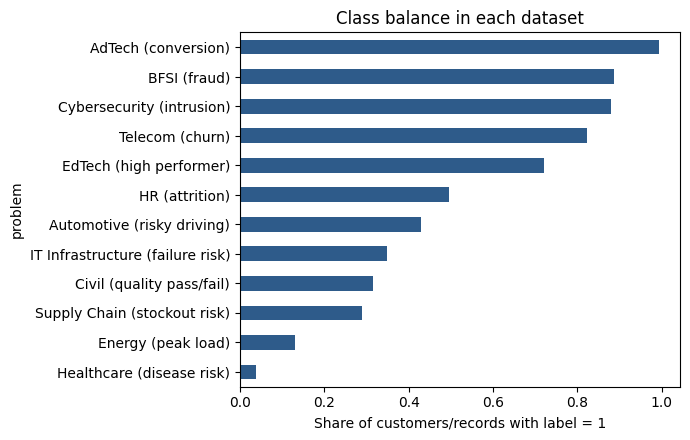

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

DATA = "../data/logistic_datasets"
OUT = "../output"
os.makedirs(OUT, exist_ok=True)

# file name -> industry (the last column of every file is the label y)
problems = {
    "supply_chain": "Supply Chain (stockout risk)",
    "bfsi": "BFSI (fraud)",
    "adtech": "AdTech (conversion)",
    "telecom": "Telecom (churn)",
    "cybersecurity": "Cybersecurity (intrusion)",
    "it_infra": "IT Infrastructure (failure risk)",
    "healthcare": "Healthcare (disease risk)",
    "hr": "HR (attrition)",
    "civil": "Civil (quality pass/fail)",
    "energy": "Energy (peak load)",
    "edtech": "EdTech (high performer)",
    "automotive": "Automotive (risky driving)",
}

rows, coef_rows = [], []
for file, title in problems.items():
    df = pd.read_csv(f"{DATA}/{file}.csv")
    target = df.columns[-1]
    y = df[target]
    X = df.drop(columns=[target])

    # stratified split keeps the same share of positives in train and test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)

    # scaler inside the pipeline, so it learns from training data only
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(X_train, y_train)

    pred = model.predict(X_test)                 # class labels (threshold 0.5)
    prob = model.predict_proba(X_test)[:, 1]     # probability of class 1
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    rows.append({
        "problem": title, "target": target, "positive_rate": round(y.mean(), 3),
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred), 3),
        "recall": round(recall_score(y_test, pred), 3),
        "f1": round(f1_score(y_test, pred), 3),
        "roc_auc": round(roc_auc_score(y_test, prob), 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
    # coefficients are on standardized features, so they can be compared with each other
    for name, c in zip(X.columns, model[-1].coef_[0]):
        coef_rows.append({"problem": title, "feature": name, "coefficient": round(c, 2)})

    print(f"{title:36s} acc={rows[-1]['accuracy']}  prec={rows[-1]['precision']}  "
          f"recall={rows[-1]['recall']}  f1={rows[-1]['f1']}  auc={rows[-1]['roc_auc']}")

results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/logistic_results.csv", index=False)
pd.DataFrame(coef_rows).to_csv(f"{OUT}/logistic_coefficients.csv", index=False)

# chart: how balanced is each label?
results.sort_values("positive_rate").plot.barh(x="problem", y="positive_rate", legend=False,
                                              color="#2E5B8A", figsize=(7, 4.5))
plt.xlabel("Share of customers/records with label = 1")
plt.title("Class balance in each dataset")
plt.tight_layout()
plt.savefig(f"{OUT}/logistic_class_balance.png", dpi=110)